In [1]:
data = 'https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv'

In [21]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

In [4]:
df = pd.read_csv(data)
df

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1
...,...,...,...,...,...,...,...,...,...
4995,organic_search,education,employed,asia,45834.0,2,2,0.37,1
4996,NaN,technology,employed,north_america,84831.0,2,5,0.51,0
4997,organic_search,finance,employed,asia,53636.0,4,6,0.75,1
4998,referral,technology,employed,africa,69430.0,4,8,0.79,1


In [7]:
df.dtypes

lead_source                     str
industry                        str
employment_status               str
location                        str
annual_income               float64
number_of_courses_viewed      int64
interaction_count             int64
lead_score                  float64
converted                     int64
dtype: object

In [9]:
df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [16]:
categorical = ['lead_source', 'industry', 'employment_status', 'location']

numerical = ['annual_income', 'number_of_courses_viewed', 'interaction_count',
       'lead_score', 'converted']

In [17]:
# filling in the missing values

for c in categorical:
    df[c] = df[c].fillna('NA')
for n in numerical:
    df[n] = df[n].fillna(0.0)

In [18]:
df.isnull().sum()

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

In [26]:
# Splitting the dataset

df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train.converted.values
y_val = df_val.converted.values
y_test = df_test.converted.values

del df_train['converted']
del df_val['converted']
del df_test['converted']

### Question 1: ROC AUC feature importance
ROC AUC could also be used to evaluate feature importance of numerical variables.

Let's do that

For each numerical variable, use it as score (aka prediction) and compute the AUC with the y variable as ground truth.
Use the training dataset for that
If your AUC is < 0.5, invert this variable by putting "-" in front

(e.g. -df_train['balance'])

AUC can go below 0.5 if the variable is negatively correlated with the target variable. You can change the direction of the correlation by negating this variable - then negative correlation becomes positive.

Which numerical variable (among the following 4) has the highest AUC?

lead_score
number_of_courses_viewed
interaction_count
annual_income

In [24]:

from sklearn.metrics import roc_auc_score

numerical = [
    'lead_score',
    'number_of_courses_viewed',
    'interaction_count',
    'annual_income'
]

for col in numerical:
    auc = roc_auc_score(df_train.converted, df_train[col])

    if auc < 0.5:
        auc = roc_auc_score(df_train.converted, -df_train[col])

    print(col, round(auc, 4))

lead_score 0.7882
number_of_courses_viewed 0.723
interaction_count 0.7649
annual_income 0.6082


### Question 2: Training the model
Apply one-hot-encoding using DictVectorizer and train the logistic regression with these parameters:

LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)


In [25]:
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression

In [30]:
dv = DictVectorizer(sparse=False)

train_dict = df_train[categorical + numerical].to_dict(orient='records')
X_train = dv.fit_transform(train_dict)

val_dicts = df_val[categorical + numerical].to_dict(orient='records')
X_val = dv.fit_transform(val_dicts)

model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_train, y_train)

y_pred = model.predict_proba(X_val)[:, 1]
auc = roc_auc_score(y_val,y_pred)
round(auc,3)

0.732

### Question 3: Precision and Recall
Now let's compute precision and recall for our model.

Evaluate the model on all thresholds from 0.0 to 1.0 with step 0.01
For each threshold, compute precision and recall
Plot them
At which threshold precision and recall curves intersect? Ignore thresholds at which both metrics are zero, and choose the threshold with the smallest absolute difference between precision and recall.

In [32]:
scores = []
thresholds = np.linspace(0,1,101)

for t in thresholds:
    actual_postive = (y_val == 1)
    actual_negative = (y_val == 0)
    
    predicted_positive = (y_pred >= t)
    predicted_negative = (y_pred < t)
    
    tp = (predicted_positive & actual_postive).sum() 
    tn = (predicted_negative & actual_negative).sum() 
    
    fp = (predicted_positive & actual_negative).sum() 
    fn = (predicted_negative & actual_postive).sum() 

    scores.append((t , tp , fp , fn , tn))

In [33]:
columns = ['thresholds','tp','fp','fn','tn']
df_scores = pd.DataFrame(scores, columns=columns)
df_scores

,thresholds,tp,fp,fn,tn
0,0.00,586,414,0,0
1,0.01,586,414,0,0
2,0.02,586,414,0,0
3,0.03,586,414,0,0
4,0.04,586,414,0,0
...,...,...,...,...,...
96,0.96,1,0,585,414
97,0.97,0,0,586,414
98,0.98,0,0,586,414
99,0.99,0,0,586,414


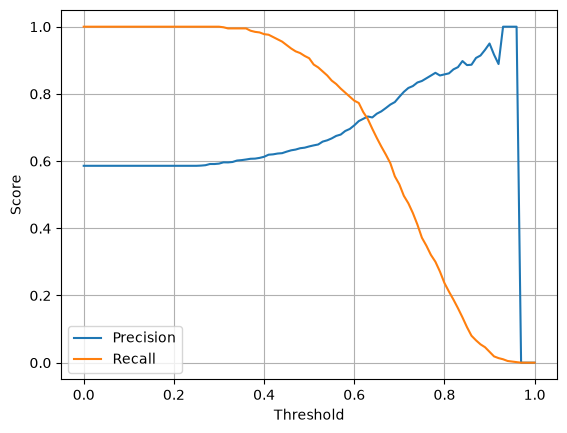

threshold    0.630000
precision    0.732759
recall       0.725256
diff         0.007503
Name: 63, dtype: float64


In [34]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

columns = ['threshold', 'tp', 'fp', 'fn', 'tn']
df_scores = pd.DataFrame(scores, columns=columns)

# Calculate precision and recall
df_scores['precision'] = (
    df_scores.tp / (df_scores.tp + df_scores.fp)
).fillna(0)

df_scores['recall'] = (
    df_scores.tp / (df_scores.tp + df_scores.fn)
).fillna(0)

# Plot precision and recall
plt.plot(df_scores.threshold, df_scores.precision, label='Precision')
plt.plot(df_scores.threshold, df_scores.recall, label='Recall')
plt.xlabel('Threshold')
plt.ylabel('Score')
plt.legend()
plt.grid()
plt.show()

# Find the threshold where precision and recall are closest
df_scores['diff'] = abs(df_scores.precision - df_scores.recall)

valid = (df_scores.precision != 0) | (df_scores.recall != 0)

best = df_scores[valid].sort_values('diff').iloc[0]

print(best[['threshold', 'precision', 'recall', 'diff']])

### Question 4: F1 score
Precision and recall are conflicting - when one grows, the other goes down. That's why they are often combined into the F1 score - a metrics that takes into account both

This is the formula for computing F1:

F
1
=
2
⋅
P
⋅
R
P
+
R

Where 
P
 is precision and 
R
 is recall.

Let's compute F1 for all thresholds from 0.0 to 1.0 with increment 0.01

At which threshold F1 is maximal?

In [35]:
# Calculate F1 score for all thresholds
df_scores['f1'] = (
    2 * df_scores.precision * df_scores.recall
    / (df_scores.precision + df_scores.recall)
).fillna(0)

# Find the threshold with the maximum F1 score
best = df_scores.loc[df_scores.f1.idxmax()]

print(best[['threshold', 'precision', 'recall', 'f1']])

threshold    0.410000
precision    0.619048
recall       0.976109
f1           0.757616
Name: 41, dtype: float64


### Question 5: 5-Fold CV
Use the KFold class from Scikit-Learn to evaluate our model on 5 different folds:

KFold(n_splits=5, shuffle=True, random_state=1)
Iterate over different folds of df_full_train
Split the data into train and validation
Train the model on train with these parameters: LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
Use AUC to evaluate the model on validation

In [38]:
from sklearn.model_selection import KFold
from sklearn.metrics import roc_auc_score
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction import DictVectorizer
from tqdm.auto import tqdm
import numpy as np

kfold = KFold(n_splits=5, shuffle=True, random_state=1)

scores = []

for train_idx, val_idx in tqdm(kfold.split(df_full_train), total=5):
    df_train = df_full_train.iloc[train_idx]
    df_val = df_full_train.iloc[val_idx]

    y_train = df_train.converted.values
    y_val = df_val.converted.values

    # Train model using the training fold
    dicts_train = df_train[categorical + numerical].to_dict(orient='records')
    dicts_val = df_val[categorical + numerical].to_dict(orient='records')

    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(dicts_train)
    X_val = dv.transform(dicts_val)

    model = LogisticRegression(
        solver='liblinear',
        C=1.0,
        max_iter=1000
    )
    model.fit(X_train, y_train)

    # Predict probabilities for validation
    y_pred = model.predict_proba(X_val)[:, 1]

    # Calculate AUC
    auc = roc_auc_score(y_val, y_pred)
    scores.append(auc)

    print(f'AUC: {auc:.4f}')

print(f'Mean AUC: {np.mean(scores):.3f}')
print(f'Standard deviation: {np.std(scores):.3f}')

  0%|          | 0/5 [00:00<?, ?it/s]

AUC: 0.7306
AUC: 0.7296
AUC: 0.7363
AUC: 0.7412
AUC: 0.7209
Mean AUC: 0.732
Standard deviation: 0.007


### Question 6: Hyperparameter Tuning
Now let's use 5-Fold cross-validation to find the best parameter C

Iterate over the following C values: [0.000001, 0.001, 1]
Initialize KFold with the same parameters as previously
Use these parameters for the model: LogisticRegression(solver='liblinear', C=C, max_iter=1000)
Compute the mean ROC AUC as well as the std (round the mean and std to 3 decimal digits).
Which C leads to the best mean ROC AUC?

0.000001
0.001
1
If you have ties, select the score with the lowest std. If you still have ties, select the smallest C.

In [40]:
for C in [0.000001, 0.001, 1]:
    scores = []

    for train_idx, val_idx in kfold.split(df_full_train):
        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]

        y_train = df_train.converted.values
        y_val = df_val.converted.values

        dicts_train = df_train[categorical + numerical].to_dict(orient='records')
        dicts_val = df_val[categorical + numerical].to_dict(orient='records')

        dv = DictVectorizer(sparse=False)
        X_train = dv.fit_transform(dicts_train)
        X_val = dv.transform(dicts_val)

        model = LogisticRegression(
            solver='liblinear',
            C=C,
            max_iter=1000
        )
        model.fit(X_train, y_train)

        y_pred = model.predict_proba(X_val)[:, 1]
        auc = roc_auc_score(y_val, y_pred)
        scores.append(auc)

    mean_auc = np.mean(scores)
    std_auc = np.std(scores)

    print(f'C={C}: mean AUC={mean_auc:.3f}, std={std_auc:.3f}')

C=1e-06: mean AUC=0.617, std=0.019
C=0.001: mean AUC=0.749, std=0.010
C=1: mean AUC=0.732, std=0.007
